# ERP ledger consolidation: merging messy exports, VAT checks and project profitability
**The situation.** A contracting company's ERP can only export its general ledger in yearly CSV chunks. The finance team receives five files that overlap at the edges, one saved in a different text encoding (its Arabic narrations turn into `???` if read naively), amounts written as text with thousands separators, and day-first dates. Management wants one clean ledger, a VAT check across the **July 2020 change of Saudi VAT from 5% to 15%**, project (cost-centre) profitability and receivables, and a reconciliation to the trial balance that the ERP prints as PDF.

> **All data here is synthetic** (`make_ledger.py`). It reproduces the structure and the problems of a real ERP export, but every company, customer, account and amount is invented. Problems are planted so every check can be verified.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import io, re, pdfplumber
import make_ledger
make_ledger.build()
files = sorted(pathlib.Path("data").glob("export_*.csv"))
coa = pd.read_csv("data/chart_of_accounts.csv", dtype={"account_code": str})
[f.name for f in files]

['export_1.csv',
 'export_2.csv',
 'export_3.csv',
 'export_4.csv',
 'export_5.csv']

## 1. Read every file robustly
Try UTF-8 first and fall back to Windows-1256 (Arabic). Then check that the schema matches before stacking.

In [2]:
def read_export(path):
    raw = path.read_bytes()
    for enc in ("utf-8-sig", "cp1256"):
        try:
            text = raw.decode(enc); break
        except UnicodeDecodeError:
            continue
    df = pd.read_csv(io.StringIO(text), dtype={"Account Code": str})
    df["source_file"], df["encoding"] = path.name, enc
    return df
parts = [read_export(f) for f in files]
schemas = {p.source_file.iloc[0]: tuple(p.columns[:-2]) for p in parts}
assert len(set(schemas.values())) == 1, "schema drift between exports"
naive = pd.read_csv(files[2], encoding="latin-1").Narration.iloc[0]
print("naive latin-1 read of file 3:", naive[:40])
print("detected encoding read     :", parts[2].Narration.iloc[0][:40])
pd.DataFrame({"file": [p.source_file.iloc[0] for p in parts], "rows": [len(p) for p in parts], "encoding": [p.encoding.iloc[0] for p in parts],
              "first_date": [p.Date.iloc[0] for p in parts], "last_date": [p.Date.iloc[-1] for p in parts]})

naive latin-1 read of file 3: ÝÇÊæÑÉ Úãíá : ãÓÊÎáÕ ÑÞã : Progress clai
detected encoding read     : فاتورة عميل : مستخلص رقم : Progress clai


,file,rows,encoding,first_date,last_date
0,export_1.csv,1495,utf-8-sig,01-01-2018,31-12-2018
1,export_2.csv,1666,utf-8-sig,02-12-2018,31-12-2019
2,export_3.csv,1657,cp1256,01-12-2019,31-12-2020
3,export_4.csv,714,utf-8-sig,03-01-2021,30-06-2021
4,export_5.csv,887,utf-8-sig,01-06-2021,30-12-2021


## 2. Normalise types and remove overlap duplicates

In [3]:
gl = pd.concat(parts, ignore_index=True)
for c in ["Debit", "Credit", "Balance"]:
    gl[c] = pd.to_numeric(gl[c].astype(str).str.replace(",", "", regex=False).replace({"nan": None, "": None}), errors="coerce").fillna(0.0)
gl["Date"] = pd.to_datetime(gl["Date"], format="%d-%m-%Y")
gl["line"] = gl.groupby(["source_file", "Voucher No"]).cumcount()
assert np.allclose(gl.Debit - gl.Credit, gl.Balance), "Balance column inconsistent with Debit - Credit"
before = len(gl)
gl = gl.drop_duplicates(subset=["Voucher No", "line", "Account Code", "Debit", "Credit"]).drop(columns=["Balance"])
print(f"{before:,} lines read, {before - len(gl):,} overlap duplicates removed, {len(gl):,} unique lines, {gl['Voucher No'].nunique():,} vouchers")
gl["narration_ar"] = gl.Narration.str.split(" : ").str[0]; gl["narration_en"] = gl.Narration.str.split(" : ", n=1).str[1]
gl = gl.merge(coa.rename(columns={"account_code": "Account Code", "type": "acct_type"})[["Account Code", "acct_type"]], on="Account Code", how="left")
print("accounts not in chart of accounts:", gl.acct_type.isna().sum())
gl.head()

6,419 lines read, 371 overlap duplicates removed, 6,048 unique lines, 2,582 vouchers
accounts not in chart of accounts: 0


,Transaction Type,Voucher No,Date,Account Code,Account Name,Cost Center,Currency,Narration,Debit,Credit,source_file,encoding,line,narration_ar,narration_en,acct_type
0,MANUAL JOURNAL,MJ18000001,2018-01-01,61040001,Bank Charges,HO - Head Office,Saudi Riyal,قيد يومية : Bank charges,3524.49,0.00,export_1.csv,utf-8-sig,0,قيد يومية,Bank charges,expense
1,MANUAL JOURNAL,MJ18000001,2018-01-01,11020001,Bank - Example National Bank,HO - Head Office,Saudi Riyal,قيد يومية : Bank charges,0.00,3524.49,export_1.csv,utf-8-sig,1,قيد يومية,Bank charges,asset
2,PAYMENT TO SUPPLIER,PS18000001,2018-01-01,21010001,Trade Payables,PRJ-03 Industrial Warehouse,Saudi Riyal,سداد للمورد : Supplier payment,223149.33,0.00,export_1.csv,utf-8-sig,0,سداد للمورد,Supplier payment,liability
3,PAYMENT TO SUPPLIER,PS18000001,2018-01-01,11020002,Bank - Example Islamic Bank,PRJ-03 Industrial Warehouse,Saudi Riyal,سداد للمورد : Supplier payment,0.00,223149.33,export_1.csv,utf-8-sig,1,سداد للمورد,Supplier payment,asset
4,RECEIPT FROM CUSTOMER,RC18000001,2018-01-01,11020001,Bank - Example National Bank,PRJ-01 Road Rehabilitation Phase 1,Saudi Riyal,تحصيل من العميل : Collection against claims,147575.42,0.00,export_1.csv,utf-8-sig,0,تحصيل من العميل,Collection against claims,asset


## 3. Integrity checks

In [4]:
bal = gl.groupby("Voucher No")[["Debit", "Credit"]].sum()
unbalanced = bal[(bal.Debit - bal.Credit).abs() > 0.005]
print(f"unbalanced vouchers: {len(unbalanced)}"); display(unbalanced.assign(difference=unbalanced.Debit - unbalanced.Credit).round(2))
print(f"total debits {gl.Debit.sum():,.2f} vs credits {gl.Credit.sum():,.2f}; difference {gl.Debit.sum() - gl.Credit.sum():,.2f}")

unbalanced vouchers: 4


,Debit,Credit,difference
Voucher No,,,
MJ18000071,3040.96,0.0,3040.96
MJ19000222,2484.14,0.0,2484.14
MJ21000506,1520.54,0.0,1520.54
MJ21000539,4934.50,0.0,4934.50


total debits 223,932,428.92 vs credits 223,920,448.78; difference 11,980.14


## 4. VAT rate check around the 1 July 2020 change
For each customer invoice, the effective rate is output VAT ÷ revenue. It must be 5% before 1 July 2020 and 15% on or after.

319 customer invoices; 6 at the wrong VAT rate; output VAT under-declared by SAR 180,618.66


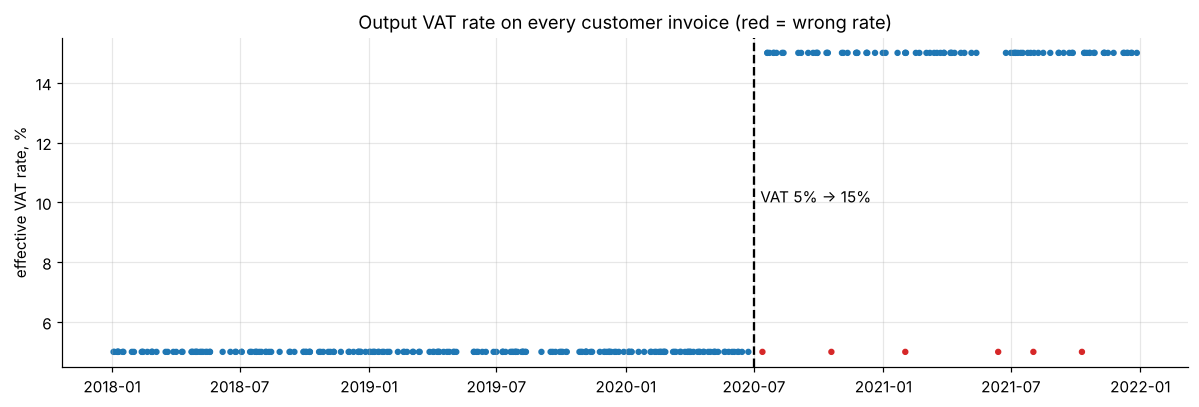

Account Code,Voucher No,Date,revenue,output_vat,rate,vat_shortfall_sar
222,CI20000223,2020-07-13,630532.04,31526.60,0.05,63053.21
241,CI20000242,2020-10-19,310350.60,15517.53,0.05,31035.06
257,CI21000258,2021-02-01,48519.65,2425.98,0.05,4851.97
277,CI21000278,2021-06-13,286680.62,14334.03,0.05,28668.06
288,CI21000289,2021-08-02,284225.98,14211.30,0.05,28422.60
299,CI21000300,2021-10-10,245877.74,12293.89,0.05,24587.77


In [5]:
inv = gl[gl["Transaction Type"] == "CUSTOMER INVOICE"].pivot_table(index=["Voucher No", "Date"], columns="Account Code", values="Credit", aggfunc="sum").reset_index()
inv["rate"] = inv["21270001"] / inv["41010001"]
inv["expected"] = np.where(inv.Date >= "2020-07-01", 0.15, 0.05)
inv["vat_shortfall_sar"] = (inv.expected - inv.rate) * inv["41010001"]
bad = inv[(inv.rate - inv.expected).abs() > 0.0005]
print(f"{len(inv)} customer invoices; {len(bad)} at the wrong VAT rate; output VAT under-declared by SAR {bad.vat_shortfall_sar.sum():,.2f}")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.scatter(inv.Date, 100 * inv.rate, s=10, c=np.where(inv.index.isin(bad.index), "C3", "C0"))
ax.axvline(pd.Timestamp("2020-07-01"), c="k", ls="--"); ax.text(pd.Timestamp("2020-07-10"), 10, "VAT 5% -> 15%")
ax.set_ylabel("effective VAT rate, %"); ax.set_title("Output VAT rate on every customer invoice (red = wrong rate)")
plt.tight_layout(); plt.savefig(IMG / "vat_rate_check.png", bbox_inches="tight"); plt.show()
bad[["Voucher No", "Date", "41010001", "21270001", "rate", "vat_shortfall_sar"]].rename(columns={"41010001": "revenue", "21270001": "output_vat"}).round(2)

In [6]:
q = gl.assign(quarter=gl.Date.dt.to_period("Q"))
vat = q[q["Account Code"].isin(["21270001", "12170001"])].groupby(["quarter", "Account Code"]).apply(lambda d: (d.Credit - d.Debit).sum() if d.name[1] == "21270001" else (d.Debit - d.Credit).sum()).unstack()
vat.columns = ["input_vat", "output_vat"]; vat["net_payable"] = vat.output_vat - vat.input_vat
vat.tail(8).round(0)

,input_vat,output_vat,net_payable
quarter,,,
2020Q1,86208.0,493034.0,406827.0
2020Q2,108075.0,272056.0,163981.0
2020Q3,398263.0,618939.0,220676.0
2020Q4,475501.0,556461.0,80960.0
2021Q1,559160.0,653149.0,93990.0
2021Q2,407827.0,216161.0,-191666.0
2021Q3,390854.0,616817.0,225963.0
2021Q4,442729.0,907787.0,465058.0


## 5. Reconcile to the ERP's PDF trial balance (November 2021)

In [7]:
rows = []
with pdfplumber.open("data/trial_balance_2021_11.pdf") as pdf:
    for ln in pdf.pages[0].extract_text().splitlines():
        m = re.match(r"^(\d{8})\s+(.+?)\s+([\d,]+\.\d{2})\s+([\d,]+\.\d{2})$", ln)
        if m: rows.append({"Account Code": m[1], "pdf_debit": float(m[3].replace(",", "")), "pdf_credit": float(m[4].replace(",", ""))})
pdf_tb = pd.DataFrame(rows).set_index("Account Code")
nov = gl[(gl.Date >= "2021-11-01") & (gl.Date <= "2021-11-30")].groupby("Account Code")[["Debit", "Credit"]].sum()
rec = pdf_tb.join(nov, how="outer").fillna(0)
rec["diff_debit"], rec["diff_credit"] = rec.pdf_debit - rec.Debit, rec.pdf_credit - rec.Credit
diff = rec[(rec.diff_debit.abs() > 0.005) | (rec.diff_credit.abs() > 0.005)]
print(f"{len(pdf_tb)} accounts on the PDF; {len(diff)} accounts differ from the consolidated CSV ledger")
diff.round(2)

20 accounts on the PDF; 3 accounts differ from the consolidated CSV ledger


,pdf_debit,pdf_credit,Debit,Credit,diff_debit,diff_credit
Account Code,,,,,,
12500101,360441.51,5.590e+05,0.0,5.590e+05,360441.51,0.00
21270001,0.00,4.472e+05,0.0,4.001e+05,0.00,47014.11
41010001,0.00,2.981e+06,0.0,2.668e+06,0.00,313427.40


In [8]:
# the differences are a single balanced entry: revenue + VAT credited, a customer debited -> an invoice missing from the CSV export
amt = diff.diff_credit.sum(); cust = diff[diff.diff_debit > 0].index[0]
print(f"missing entry: Dr {cust} {diff.loc[cust, 'diff_debit']:,.2f} / Cr revenue {diff.loc['41010001', 'diff_credit']:,.2f} + VAT {diff.loc['21270001', 'diff_credit']:,.2f}")
print(f"implied VAT rate {diff.loc['21270001', 'diff_credit'] / diff.loc['41010001', 'diff_credit']:.1%} -> a customer invoice dropped by the export")

missing entry: Dr 12500101 360,441.51 / Cr revenue 313,427.40 + VAT 47,014.11
implied VAT rate 15.0% -> a customer invoice dropped by the export


## 6. Project profitability and receivables

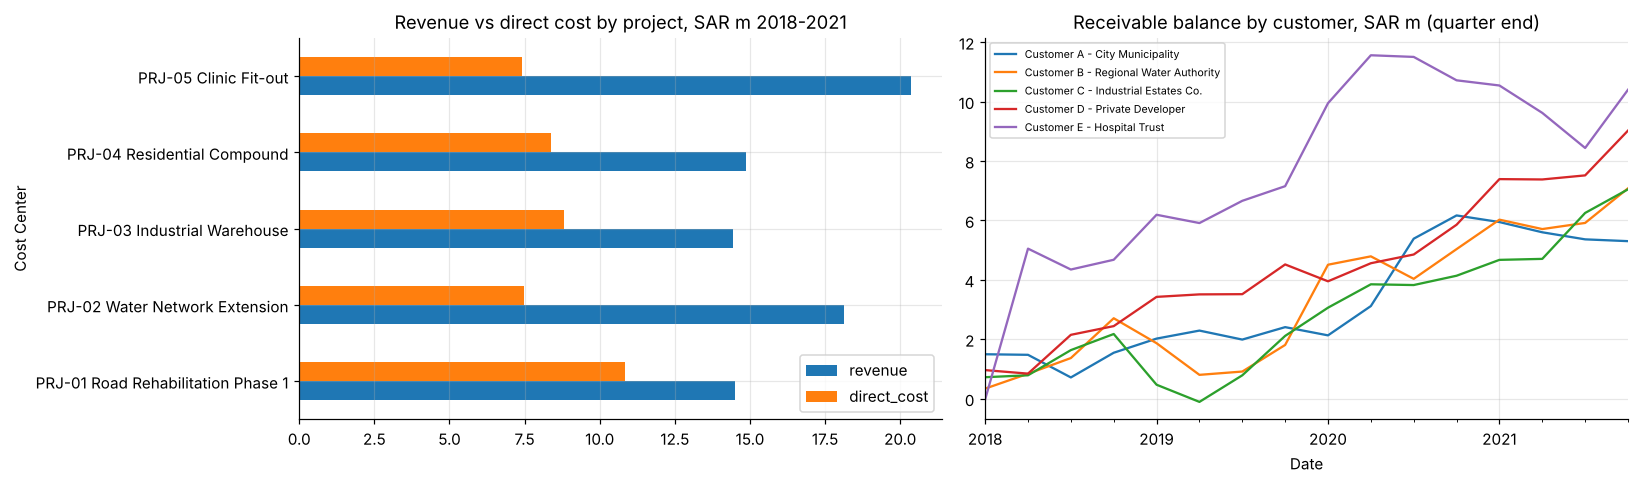

,revenue,direct_cost,gross_margin,margin_%,overhead_alloc,net_margin_%
Cost Center,,,,,,
PRJ-01 Road Rehabilitation Phase 1,1.449e+07,1.084e+07,3.652e+06,25.2,1.371e+06,15.7
PRJ-03 Industrial Warehouse,1.445e+07,8.815e+06,5.630e+06,39.0,1.367e+06,29.5
PRJ-04 Residential Compound,1.487e+07,8.363e+06,6.508e+06,43.8,1.407e+06,34.3
PRJ-02 Water Network Extension,1.811e+07,7.492e+06,1.062e+07,58.6,1.714e+06,49.2
PRJ-05 Clinic Fit-out,2.037e+07,7.415e+06,1.296e+07,63.6,1.928e+06,54.1


In [9]:
proj = gl[gl["Cost Center"] != "HO - Head Office"]
pl = proj.pivot_table(index="Cost Center", columns="acct_type", values=["Debit", "Credit"], aggfunc="sum", fill_value=0)
prof = pd.DataFrame({"revenue": pl[("Credit", "revenue")] - pl[("Debit", "revenue")], "direct_cost": pl[("Debit", "cost")] - pl[("Credit", "cost")]})
prof["gross_margin"] = prof.revenue - prof.direct_cost; prof["margin_%"] = 100 * prof.gross_margin / prof.revenue
ho = gl[(gl["Cost Center"] == "HO - Head Office") & (gl.acct_type == "expense")]
overhead = (ho.Debit - ho.Credit).sum()
prof["overhead_alloc"] = overhead * prof.revenue / prof.revenue.sum(); prof["net_margin_%"] = 100 * (prof.gross_margin - prof.overhead_alloc) / prof.revenue
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
(prof[["revenue", "direct_cost"]] / 1e6).plot.barh(ax=axes[0], title="Revenue vs direct cost by project, SAR m 2018-2021")
ar_codes = [c for c in coa.account_code if c.startswith("125")]
ar = gl[gl["Account Code"].isin(ar_codes)].sort_values("Date")
ar_bal = ar.assign(net=ar.Debit - ar.Credit).groupby([pd.Grouper(key="Date", freq="QE"), "Account Name"])["net"].sum().unstack().fillna(0).cumsum() / 1e6
ar_bal.columns = [c.replace("ACC.R - ", "") for c in ar_bal.columns]
ar_bal.plot(ax=axes[1], title="Receivable balance by customer, SAR m (quarter end)"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(IMG / "projects_receivables.png", bbox_inches="tight"); plt.show()
prof.round(1).sort_values("net_margin_%")

In [10]:
gl.drop(columns=["line"]).to_csv("data/ledger_consolidated.csv.gz", index=False, compression="gzip")
print("clean ledger saved:", len(gl), "lines")

clean ledger saved: 6048 lines


## Findings
* **Consolidation:** five exports (6,419 lines) became one ledger of 6,048 lines and 2,582 vouchers. 371 lines duplicated across overlapping months were removed. Encoding detection recovered the Arabic narrations in the Windows-1256 file, which a naive latin-1 read turns into gibberish (the original problem behind the `???` text). Every line maps to the chart of accounts.
* **Integrity:** 4 manual journals are unbalanced, each missing its credit leg (SAR 11,980.14 in total). This exactly explains the gap between total debits and credits.
* **VAT:** 6 of the 319 customer invoices issued after 1 July 2020 still charge 5%, so output VAT is **under-declared by SAR 180,618.66**. That calls for a correction, and possibly a voluntary disclosure, in the VAT returns.
* **PDF reconciliation:** the November 2021 trial balance differs from the CSV ledger in exactly three accounts (a customer, revenue and output VAT). Together they form one invoice of SAR 360,441.51 (15% VAT) that the ERP holds but the CSV export dropped. Without this check the export would silently understate revenue.
* **Management view:** project gross margins and receivable balances by customer come out of the same clean ledger, with head-office overhead allocated by revenue. Because the data are synthetic, the margins illustrate the method, not a real business.
* **Reusable:** the same pipeline (encoding detection, schema check, overlap de-duplication, voucher balancing, rate checks by date, PDF reconciliation) applies to any ERP that exports in chunks.